In [5]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle
import os
from sklearn.metrics import auc

**Minimal example**

In [2]:
example_data = np.random.randint(2, size=45)
example_data = example_data.reshape(3, 15)
print(example_data)

[[0 0 0 0 0 1 1 0 0 0 1 0 1 0 0]
 [0 0 0 1 1 1 1 1 0 1 1 0 1 1 0]
 [0 1 1 1 1 0 0 1 0 0 1 0 1 0 1]]


In [6]:
example_coo = sp.sparse.coo_matrix(example_data)
(example_train, example_test) = cross_validation.random_train_test_split(example_coo, test_percentage=0.2)
example_train_csr = example_train.tocsr()
example_test_csr = example_test.tocsr()

In [7]:
print(example_train.toarray())

[[0 0 0 0 0 0 1 0 0 0 1 0 1 0 0]
 [0 0 0 1 1 0 0 1 0 1 0 0 1 1 0]
 [0 1 1 1 0 0 0 1 0 0 1 0 1 0 1]]


In [8]:
print(example_test.toarray())

[[0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]]


In [9]:
example_model = LightFM(no_components=1, loss='warp')
example_model.fit(example_train, epochs=1)

In [10]:
n_rows, n_cols = example_train_csr.shape
train_data_np = example_train.toarray()
test_data_np = example_test.toarray()
ordered_list = []
test_count_list = []
for row in range(n_rows):
    print('row              ', row)
    #known positives in train set
    train_kp = np.where(train_data_np[row]==1)[0]
    print('train_kp         ', train_kp)
    #every DHS index
    full_ind = np.arange(n_cols)
#     print(full_ind)
    #only the DHS indices that are not known positives in the train set
    test_only_ind = np.delete(full_ind, train_kp)
    print('test_only_ind    ', test_only_ind)
    #For each biosample, the DHS values for each DHS that does not exist as known positive in train set
    test_only_data = test_data_np[row, test_only_ind]
    print('test_only_data   ', test_only_data)
    #For each biosample, counting the number of true positives in test set only
    test_only_count = np.sum(test_only_data)
    test_count_list.append(test_only_count)
    print('test_only_count  ', test_only_count)
    #For each biosample, predicting scores for only dhs indices that are not known positives in train set
    scores = example_model.predict(row, test_only_ind)
    print('scores           ', scores)
    #ordering scores
    ordered = np.argsort(-scores)
    print('ordered          ', ordered)
    #ordering DHS values that were not known positives in train set 
    ordered_test_only = test_only_data[ordered]
    print('ordered_test_only', ordered_test_only)
    print()
    ordered_list.append(ordered_test_only)
for k in np.arange(1,16):
    print()
    print('k =', k)
    for row in range(n_rows):
        #for each biosample, calculates precision for the top k DHS recs
        print('precision for row', row, '=', np.sum(ordered_list[row][:k])/k)
        print('recall for row', row, '=', np.sum(ordered_list[row][:k])/test_count_list[row])

row               0
train_kp          [ 6 10 12]
test_only_ind     [ 0  1  2  3  4  5  7  8  9 11 13 14]
test_only_data    [0 0 0 0 0 1 0 0 0 0 0 0]
test_only_count   1
scores            [-0.24990155 -0.18993399 -0.2763159  -0.00414093 -0.45077613 -0.5667187
 -0.10237791 -0.0805193  -0.5116691  -0.4100774  -0.09703732 -0.16159007]
ordered           [ 3  7 10  6 11  1  0  2  9  4  8  5]
ordered_test_only [0 0 0 0 0 0 0 0 0 0 0 1]

row               1
train_kp          [ 3  4  7  9 12 13]
test_only_ind     [ 0  1  2  5  6  8 10 11 14]
test_only_data    [0 0 0 1 1 0 1 0 0]
test_only_count   3
scores            [-0.32116115 -0.25725475 -0.32970053 -0.60412914 -0.24422649 -0.15622485
 -0.23319796 -0.46347684 -0.21610902]
ordered           [5 8 6 4 1 0 2 7 3]
ordered_test_only [0 0 1 1 0 0 0 0 1]

row               2
train_kp          [ 1  2  3  7 10 12 14]
test_only_ind     [ 0  4  5  6  8  9 11 13]
test_only_data    [0 1 0 0 0 0 0 0]
test_only_count   1
scores            [-0.3383859  -0.51

**Calculating precision for example data with LightFM function**

In [11]:
example_precision_list = []
example_recall_list = []
for k_val in np.arange(1, 15):
    example_precision_list.append(precision_at_k(example_model, example_test, train_interactions=example_train, k=k_val))
    example_recall_list.append(recall_at_k(example_model, example_test, train_interactions=example_train, k=k_val))

In [12]:
lightfm_p_mean = np.mean(example_precision_list, axis=1)
print(lightfm_p_mean)
lightfm_r_mean = np.mean(example_recall_list, axis=1)
print()
print(lightfm_r_mean)

[0.         0.         0.11111111 0.16666667 0.13333334 0.16666667
 0.14285715 0.125      0.14814815 0.13333334 0.12121212 0.1388889
 0.12820514 0.11904762]

[0.         0.         0.11111111 0.22222222 0.22222222 0.55555556
 0.55555556 0.55555556 0.66666667 0.66666667 0.66666667 1.
 1.         1.        ]


**Homemade function to calculate precision**

In [19]:
def pr(model, test_data, train_data, k_vals):
    n_rows, n_cols = test_data.shape
    test_data_np = test_data.toarray()
    train_data_np = train_data.toarray()
    ordered_list = []
    test_count_list = []
    for row in range(n_rows):
        #known positives in train set
        train_kp = np.where(train_data_np[row]==1)[0]
        #every DHS index
        full_ind = np.arange(n_cols)
        #only the DHS indices that are not known positives in the train set
        test_only_ind = np.delete(full_ind, train_kp)
        #For each biosample, the DHS values for each DHS that does not exist as known positive in train set
        test_only_data = test_data_np[row, test_only_ind]
        #For each biosample, counting the number of true positives in test set only
        test_only_count = np.sum(test_only_data)
        test_count_list.append(test_only_count)
        #For each biosample, predicting scores for only dhs indices that are not known positives in train set
        scores = model.predict(row, test_only_ind)
        #ordering scores
        ordered = np.argsort(-scores)
        #ordering DHS values that were not known positives in train set 
        ordered_test_only = test_only_data[ordered]
        ordered_list.append(ordered_test_only)
    precision = []
    recall = []
    for k in k_vals:
#         print(k)
        k_precision = []
        k_recall = []
        for row in range(n_rows):
#             k_precision.append(np.mean(ordered_list[row][:k])) #this is how we were going to calculate precision
            #for each biosample, calculates precision for the top k DHS recs
            count = np.sum(ordered_list[row][:k])
            k_precision.append(count/k) #this is how lightFM calculates precision
            k_recall.append(count/test_count_list[row])
        precision.append(k_precision)
        recall.append(k_recall)
    return precision, recall

In [14]:
homemade_precision, homemade_recall = pr(example_model, example_test, example_train, np.arange(1, 15))
homemade_p_mean = np.mean(homemade_precision, axis=1)
homemade_r_mean = np.mean(homemade_recall, axis=1)
print('Homemade Precision:')
print(homemade_p_mean)
print('LightFM Precision:')
print(lightfm_p_mean)
print('Difference between Homemade and LightFM Precision:')
print(np.round(homemade_p_mean - lightfm_p_mean, 9))
print()
print('Homemade Recall:')
print(homemade_r_mean)
print('LightFM Recall:')
print(lightfm_r_mean)
print('Difference between Homemade and LightFM Recall:')
print(np.round(homemade_r_mean - lightfm_r_mean, 9))

Homemade Precision:
[0.         0.         0.11111111 0.16666667 0.13333333 0.16666667
 0.14285714 0.125      0.14814815 0.13333333 0.12121212 0.13888889
 0.12820513 0.11904762]
LightFM Precision:
[0.         0.         0.11111111 0.16666667 0.13333334 0.16666667
 0.14285715 0.125      0.14814815 0.13333334 0.12121212 0.1388889
 0.12820514 0.11904762]
Difference between Homemade and LightFM Precision:
[ 0.e+00  0.e+00 -1.e-09 -5.e-09 -7.e-09 -5.e-09 -6.e-09  0.e+00 -1.e-09
 -7.e-09 -4.e-09 -7.e-09 -7.e-09 -0.e+00]

Homemade Recall:
[0.         0.         0.11111111 0.22222222 0.22222222 0.55555556
 0.55555556 0.55555556 0.66666667 0.66666667 0.66666667 1.
 1.         1.        ]
LightFM Recall:
[0.         0.         0.11111111 0.22222222 0.22222222 0.55555556
 0.55555556 0.55555556 0.66666667 0.66666667 0.66666667 1.
 1.         1.        ]
Difference between Homemade and LightFM Recall:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [15]:
print(homemade_precision)
print()
print(homemade_recall)

[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.3333333333333333, 0.0], [0.0, 0.5, 0.0], [0.0, 0.4, 0.0], [0.0, 0.3333333333333333, 0.16666666666666666], [0.0, 0.2857142857142857, 0.14285714285714285], [0.0, 0.25, 0.125], [0.0, 0.3333333333333333, 0.1111111111111111], [0.0, 0.3, 0.1], [0.0, 0.2727272727272727, 0.09090909090909091], [0.08333333333333333, 0.25, 0.08333333333333333], [0.07692307692307693, 0.23076923076923078, 0.07692307692307693], [0.07142857142857142, 0.21428571428571427, 0.07142857142857142]]

[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.3333333333333333, 0.0], [0.0, 0.6666666666666666, 0.0], [0.0, 0.6666666666666666, 0.0], [0.0, 0.6666666666666666, 1.0], [0.0, 0.6666666666666666, 1.0], [0.0, 0.6666666666666666, 1.0], [0.0, 1.0, 1.0], [0.0, 1.0, 1.0], [0.0, 1.0, 1.0], [1.0, 1.0, 1.0], [1.0, 1.0, 1.0], [1.0, 1.0, 1.0]]


**Testing Homemade precision and recall function with DHS epochs=15, k=16 dimensions, a=1e-4 model**

In [6]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001.pickle', 'rb')
model_e15_d16_reg0001=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001.pickle', 'rb')
data_e15_d16_reg0001=pickle.load(pickle_in)

In [7]:
n_biosamples, n_DHSs = data_e15_d16_reg0001['test'].shape

In [26]:
dhs_test_csr = data_e15_d16_reg0001['test'].tocsr()[0, :]
dhs_train_csr = data_e15_d16_reg0001['train'].tocsr()[0, :]
n_rows, n_cols = dhs_test_csr.shape
train_data_np = dhs_train_csr.toarray()
test_data_np = dhs_test_csr.toarray()
ordered_list = []
test_count_list = []
for row in range(n_rows):
    print('row              ', row)
    #known positives in train set
    train_kp = np.where(train_data_np[row]==1)[0]
    print('train_kp         ', train_kp)
    print('len(train_kp)    ', len(train_kp))
    #every DHS index
    full_ind = np.arange(n_cols)
#     print(full_ind)
    #only the DHS indices that are not known positives in the train set
    test_only_ind = np.delete(full_ind, train_kp)
    print('test_only_ind    ', test_only_ind[:21])
    #print number of shared indices between train and test
    print('# train in test  ', len(set(test_only_ind)) - len(set(test_only_ind) - set(train_kp)))
    #For each biosample, the DHS values for each DHS that does not exist as known positive in train set
    test_only_data = test_data_np[row, test_only_ind]
    print('test_only_data   ', test_only_data)
    #For each biosample, counting the number of true positives in test set only
    test_only_count = np.sum(test_only_data)
    test_count_list.append(test_only_count)
    print('test_only_count  ', test_only_count)
    #For each biosample, predicting scores for only dhs indices that are not known positives in train set
    scores = model_e15_d16_reg0001.predict(row, test_only_ind)
    print('scores           ', scores)
    #ordering scores
    ordered = np.argsort(-scores)
    print('ordered          ', ordered[:15])
    #ordering DHS values that were not known positives in train set 
    ordered_test_only = test_only_data[ordered]
    print('ordered_test_only', ordered_test_only[:15])
    print()
    ordered_list.append(ordered_test_only)
for k in np.arange(1,16):
    print()
    print('k =', k)
    for row in range(n_rows):
        #for each biosample, calculates precision for the top k DHS recs
        print('precision for row', row, '=', np.sum(ordered_list[row][:k])/k)
        print('recall for row', row, '=', np.sum(ordered_list[row][:k])/test_count_list[row])

row               0
train_kp          [     20      53      63 ... 3584097 3587294 3589366]
len(train_kp)     66266
test_only_ind     [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 21]
# train in test   0
test_only_data    [0 0 0 ... 0 0 0]
test_only_count   16652
scores            [-13.269282 -13.233792 -13.246693 ... -13.210524 -13.25485  -13.275815]
ordered           [2124006 1518844 3405656 1479949 1876399 2017512 1302085 2822988 3047949
 2168107 1523615 1493924 2276670  555464  279646]
ordered_test_only [1 1 1 0 1 1 1 1 1 1 1 1 1 1 1]


k = 1
precision for row 0 = 1.0
recall for row 0 = 6.005284650492433e-05

k = 2
precision for row 0 = 1.0
recall for row 0 = 0.00012010569300984866

k = 3
precision for row 0 = 1.0
recall for row 0 = 0.000180158539514773

k = 4
precision for row 0 = 0.75
recall for row 0 = 0.000180158539514773

k = 5
precision for row 0 = 0.8
recall for row 0 = 0.00024021138601969732

k = 6
precision for row 0 = 0.8333333333333334
recall for row 0 = 0

In [16]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, n_DHSs, 10000)))
print(len(k_vals))

1359


In [20]:
p_test_e15_d16_reg0001, r_test_e15_d16_reg0001 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['test'], data_e15_d16_reg0001['train'], k_vals)

In [21]:
p_train_e15_d16_reg0001, r_train_e15_d16_reg0001 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['train'], data_e15_d16_reg0001['test'], k_vals)

In [20]:
print('Test precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(p_test_e15_d16_reg0001[0]))
print(np.mean(p_test_e15_d16_reg0001[1]))
print(np.mean(p_test_e15_d16_reg0001[2]))
print(np.mean(p_test_e15_d16_reg0001[3]))
print(np.mean(p_test_e15_d16_reg0001[4]))
print(np.mean(p_test_e15_d16_reg0001[5]))
print(np.mean(p_test_e15_d16_reg0001[6]))
print(np.mean(p_test_e15_d16_reg0001[7]))
print()
print('Train precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(p_train_e15_d16_reg0001[0]))
print(np.mean(p_train_e15_d16_reg0001[1]))
print(np.mean(p_train_e15_d16_reg0001[2]))
print(np.mean(p_train_e15_d16_reg0001[3]))
print(np.mean(p_train_e15_d16_reg0001[4]))
print(np.mean(p_train_e15_d16_reg0001[5]))
print(np.mean(p_train_e15_d16_reg0001[6]))
print(np.mean(p_train_e15_d16_reg0001[7]))
print()
print('Test recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(r_test_e15_d16_reg0001[0]))
print(np.mean(r_test_e15_d16_reg0001[1]))
print(np.mean(r_test_e15_d16_reg0001[2]))
print(np.mean(r_test_e15_d16_reg0001[3]))
print(np.mean(r_test_e15_d16_reg0001[4]))
print(np.mean(r_test_e15_d16_reg0001[5]))
print(np.mean(r_test_e15_d16_reg0001[6]))
print(np.mean(r_test_e15_d16_reg0001[7]))
print()
print('Train recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(r_train_e15_d16_reg0001[0]))
print(np.mean(r_train_e15_d16_reg0001[1]))
print(np.mean(r_train_e15_d16_reg0001[2]))
print(np.mean(r_train_e15_d16_reg0001[3]))
print(np.mean(r_train_e15_d16_reg0001[4]))
print(np.mean(r_train_e15_d16_reg0001[5]))
print(np.mean(r_train_e15_d16_reg0001[6]))
print(np.mean(r_train_e15_d16_reg0001[7]))

Test precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
0.990450204638472
0.9792633015006822
0.9686357435197817
0.9335989085948158
0.5124402455661664
0.11938038199181446
0.019029542974079126
0.005794269672474504

Train precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
0.9986357435197817
0.9972714870395635
0.9927285129604366
0.9883506139154161
0.9299882673942702
0.40594755798090043
0.07612296316507502
0.023177077550453236

Test recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
7.014239846411668e-05
0.0006871112633126575
0.006751147230466397
0.06386829055438017
0.30468423844203674
0.6281848351082219
0.9357322548664392
1.0

Train recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
1.772678e-05
0.00017703885
0.0017546489
0.017424323
0.159253
0.5663845
0.9372475
1.0


In [21]:
#Checking precision @ k=n_DHSs with approximation
test_interactions = data_e15_d16_reg0001['test'].tocsr().size
train_interactions = data_e15_d16_reg0001['train'].tocsr().size
test_interactions_per_line = test_interactions/n_biosamples
train_interactions_per_line = train_interactions/n_biosamples
print('Test Precision @ k=n_DHSs', test_interactions_per_line/n_DHSs)
print('Train Precision @ k=n_DHSs', train_interactions_per_line/n_DHSs)

Test Precision @ k=n_DHSs 0.005794269672474504
Train Precision @ k=n_DHSs 0.023177077550453236


In [28]:
total_interactions = test_interactions+train_interactions
sparsity = total_interactions/(n_biosamples*n_DHSs)
print(sparsity)

0.02897134722292774


In [42]:
precision_test_mean = []
for i in range(len(p_test_e15_d16_reg0001)):
    precision_test_mean.append(np.mean(p_test_e15_d16_reg0001[i]))
precision_train_mean = []
for i in range(len(p_train_e15_d16_reg0001)):
    precision_train_mean.append(np.mean(p_train_e15_d16_reg0001[i]))    
recall_test_mean = []
for i in range(len(r_test_e15_d16_reg0001)):
    recall_test_mean.append(np.mean(r_test_e15_d16_reg0001[i]))
recall_train_mean = []
for i in range(len(r_train_e15_d16_reg0001)):
    recall_train_mean.append(np.mean(r_train_e15_d16_reg0001[i])) 

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

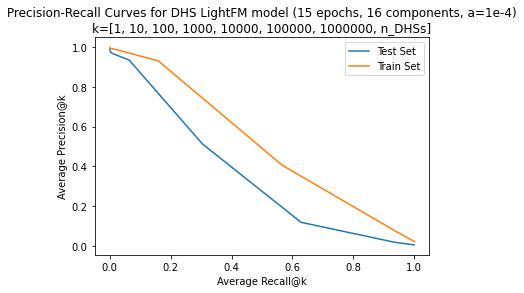

In [23]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(recall_test_mean, precision_test_mean)
plt.plot(recall_train_mean, precision_train_mean)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

In [31]:
auc_test = auc(recall_test_mean, precision_test_mean)
print(auc_test)
auc_train = auc(recall_train_mean, precision_train_mean)
print(auc_train)

0.35923210819272305
0.5177453817491925


**Testing Homemade precision and recall function with DHS Signal Data with model epochs=15, k=16 dimensions, a=1e-4 model**

In [21]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_signal_model_e15_d16_reg0.0001_lr01_rs3.pickle', 'rb')
signal_model_e15_d16_reg0001_lr01_rs3=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_signal_data_e15_d16_reg0.0001_lr01_rs3.pickle', 'rb')
signal_data_e15_d16_reg0001_lr01_rs3=pickle.load(pickle_in)

In [38]:
dhs_test_csr = signal_data_e15_d16_reg0001_lr01_rs3['test'].tocsr()[0, :]
dhs_train_csr = signal_data_e15_d16_reg0001_lr01_rs3['train'].tocsr()[0, :]
n_rows, n_cols = dhs_test_csr.shape
test_data_np = dhs_test_csr.toarray()
train_data_np = dhs_train_csr.toarray()
ordered_list = []
test_count_list = []
for row in range(n_rows):
    print('row              ', row)
    #known positives in train set
    train_kp = np.where(train_data_np[row]>0)[0]
    print('train_kp         ', train_kp)
    print('len(trait_kp)    ', len(train_kp))
    #every DHS index
    full_ind = np.arange(n_cols)
    #only the DHS indices that are not known positives in the train set
    test_only_ind = np.delete(full_ind, train_kp)
    print('test_only_ind    ', test_only_ind[:21])
    print('# train in test  ', len(set(test_only_ind)) - len(set(test_only_ind) - set(train_kp)))
    #For each biosample, the DHS values for each DHS that does not exist as known positive in train set
    test_only_data = test_data_np[row, test_only_ind]
    print('test_only_data   ', test_only_data)
    #For each biosample, counting the number of true positives in test set only
    test_only_count = np.count_nonzero(test_only_data > 0)
    test_count_list.append(test_only_count)
    print('test_only_count  ', test_only_count)
    #For each biosample, predicting scores for only dhs indices that are not known positives in train set
    scores = signal_model_e15_d16_reg0001_lr01_rs3.predict(row, test_only_ind)
    print('scores           ', scores)
    #ordering scores                                                                
    ordered = np.argsort(-scores)
    print('ordered          ', ordered[:25])
    #ordering DHS values that were not known positives in train set
    ordered_test_only = test_only_data[ordered]
    ordered_list.append(ordered_test_only)
    print('ordered_test_only', ordered_test_only[:25])
    print()
precision = []
recall = []
for k in np.arange(1, 16):
    k_precision = []
    k_recall = []
    print('k =', k)
    for row in range(n_rows):
        #for each biosample, calculates precision for the top k DHS recs
        count = np.count_nonzero(ordered_list[row][:k] > 0)
        k_precision.append(count/k) #this is how lightFM calculates precision
        k_recall.append(count/test_count_list[row])
        print('precision for row', row, '=', count/k)
        print('recall for row', row, '=', count/test_count_list[row])
        print()
    precision.append(k_precision)                                                   
    recall.append(k_recall)

row               0
train_kp          [     20      53      63 ... 3587294 3587297 3589366]
len(trait_kp)     66332
test_only_ind     [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 21]
# train in test   0
test_only_data    [0. 0. 0. ... 0. 0. 0.]
test_only_count   16586
scores            [-0.9652379  -0.9639269  -0.9360785  ... -0.92863363 -0.9431981
 -0.9428646 ]
ordered           [2864678 3497425  556059 1640953   62446 1262972 1200319 2153224  123543
  966140 1629620 2166102 3125849 1234441  265551 1904039 3456717 1230079
  673495 2534213 3068006 2412074 1511512 2016671 1626686]
ordered_test_only [54.7087   7.68991  2.09876 17.6279  11.9787  34.0695   7.29172  0.
  3.06933  8.46968 18.2998  10.5601   4.99388 33.887    7.524   18.1505
  5.80683 30.3283   0.      23.4679  31.0997  16.8647  33.1155  24.3223
 12.7336 ]

k = 1
precision for row 0 = 1.0
recall for row 0 = 6.02918123718799e-05

k = 2
precision for row 0 = 1.0
recall for row 0 = 0.0001205836247437598

k = 3
pr

**Comparing embeddings between signal and presence/absence data**

In [32]:
signal_user_b, signal_user_e = signal_model_e15_d16_reg0001_lr01_rs3.get_user_representations()
signal_item_b, signal_item_e = signal_model_e15_d16_reg0001_lr01_rs3.get_item_representations()

In [34]:
user_b, user_e = model_e15_d16_reg0001.get_user_representations()
item_b, item_e = model_e15_d16_reg0001.get_item_representations()

In [36]:
print(signal_user_e)
print()
print(user_e)
print()
print(signal_item_e)
print()
print(item_e)

[[-0.13872027 -0.13372451  0.14638442 ... -0.16709375  0.13288255
   0.13980094]
 [-0.15467899 -0.1687192   0.15444186 ... -0.16886763  0.15041496
   0.15083268]
 [-0.1610472  -0.15466176  0.17369421 ... -0.19378915  0.15870841
   0.16715582]
 ...
 [-0.13311364 -0.1387597   0.1321878  ... -0.15017109  0.14072336
   0.12884668]
 [-0.14047739 -0.13708305  0.13557863 ... -0.15078293  0.15330581
   0.12690146]
 [-0.13752417 -0.13407928  0.13438515 ... -0.14673044  0.15229745
   0.12579176]]

[[-2.1138025e-09 -4.0272871e-10  4.1239581e-09 ...  1.2668850e-09
  -2.3141626e-09  3.3952958e-09]
 [-6.3887495e-10  6.4651734e-10  4.3743409e-09 ...  1.4237002e-09
  -3.1071963e-09  1.5738004e-09]
 [-1.6628866e-10 -7.7863282e-10  6.7797972e-09 ...  2.5838838e-09
  -2.4571485e-09  3.4877945e-09]
 ...
 [-4.0140207e-09  1.0742750e-09  2.7537492e-09 ...  2.0706259e-09
  -3.3659839e-09  5.8992269e-09]
 [ 1.7842416e-09  8.3465274e-10  2.8063452e-09 ...  2.6176254e-09
  -1.6286791e-09  3.1994525e-09]
 [-1.62

**Precision values with LightFM function**

In [2]:
pickle_in = open('/home/ctrader/Hold/DHS/precision_CT20211028.pickle', 'rb')
lightfm_precision=pickle.load(pickle_in)

In [6]:
lightfm_precision_test_mean = []
for i in range(len(lightfm_precision)):
    lightfm_precision_test_mean.append(np.mean(lightfm_precision[i]))

In [7]:
print(lightfm_precision_test_mean)

[0.9904502, 0.9792633, 0.96855384, 0.93355393, 0.5124394]


**Precision and recall values from homemade function run on cluster**

In [11]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0001_test_precision_recall.pickle', 'rb')
pr_cluster_test_e15_d16_reg0001=pickle.load(pickle_in)
p_cluster_test_e15_d16_reg0001, r_cluster_test_e15_d16_reg0001 = pr_cluster_test_e15_d16_reg0001

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0001_train_precision_recall.pickle', 'rb')
pr_cluster_train_e15_d16_reg0001=pickle.load(pickle_in)
p_cluster_train_e15_d16_reg0001, r_cluster_train_e15_d16_reg0001 = pr_cluster_train_e15_d16_reg0001

In [13]:
precision_cluster_test_mean = []
for i in range(len(p_cluster_test_e15_d16_reg0001)):
    precision_cluster_test_mean.append(np.mean(p_cluster_test_e15_d16_reg0001[i]))
precision_cluster_train_mean = []
for i in range(len(p_cluster_train_e15_d16_reg0001)):
    precision_cluster_train_mean.append(np.mean(p_cluster_train_e15_d16_reg0001[i]))    
recall_cluster_test_mean = []
for i in range(len(r_cluster_test_e15_d16_reg0001)):
    recall_cluster_test_mean.append(np.mean(r_cluster_test_e15_d16_reg0001[i]))
recall_cluster_train_mean = []
for i in range(len(r_cluster_train_e15_d16_reg0001)):
    recall_cluster_train_mean.append(np.mean(r_cluster_train_e15_d16_reg0001[i])) 

In [17]:
print('Test precision:', precision_cluster_test_mean)
print()
print('Test recall:', recall_cluster_test_mean)
print()
print('Train precision:', precision_cluster_train_mean)
print()
print('Train recall:', recall_cluster_train_mean)
print()

Test precision: [0.990450204638472, 0.9792633015006822, 0.9686357435197817, 0.9335989085948158, 0.5124402455661664, 0.11938038199181446, 0.019029542974079126, 0.005794269672474504]

Test recall: [7.014239846411668e-05, 0.0006871112633126575, 0.006751147230466397, 0.06386829055438017, 0.30468423844203674, 0.6281848351082219, 0.9357322548664392, 1.0]

Train precision: [0.9986357435197817, 0.9972714870395635, 0.9927285129604366, 0.9883506139154161, 0.9299882673942702, 0.40594755798090043, 0.07612296316507502, 0.023177077550453236]

Train recall: [1.772678e-05, 0.00017703885, 0.0017546489, 0.017424323, 0.159253, 0.5663845, 0.9372475, 1.0]



**Testing precision for individual biosamples**

In [204]:
p1 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['test'].tocsr()[0, :], data_e15_d16_reg0001['train'].tocsr()[0, :], [1, 10, 100, 1000, 10000])
p2 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['train'].tocsr()[0, :], data_e15_d16_reg0001['test'].tocsr()[0, :], [1, 10, 100, 1000, 10000])

0
0


In [205]:
p1

[[1.0], [0.9], [0.88], [0.802], [0.3596]]

In [206]:
p2

[[1.0], [1.0], [0.97], [0.973], [0.8462]]

In [52]:
import time
t = time.time()
data_e15_d16_reg0001['train'].toarray()
print(time.time() - t)
t = time.time()
data_e15_d16_reg0001['train'].tocsr()[0, :]
print((time.time() - t)*733)

19.8097140789032
5865.628071784973


**Testing random recs pr**

In [37]:
full_data = data_e15_d16_reg0001['test'] + data_e15_d16_reg0001['train']

In [30]:
data_e15_d16_reg0001['test']

<733x3591898 sparse matrix of type '<class 'numpy.int64'>'
	with 15255508 stored elements in COOrdinate format>

In [31]:
data_e15_d16_reg0001['train']

<733x3591898 sparse matrix of type '<class 'numpy.float32'>'
	with 61022029 stored elements in COOrdinate format>

In [32]:
full_data

<733x3591898 sparse matrix of type '<class 'numpy.float64'>'
	with 76277537 stored elements in Compressed Sparse Row format>

In [38]:
def pr_random_recs(model, data, k_vals):
    n_rows, n_cols = data.shape
    data_np = data.toarray()
    unordered_list = []
    row_count_list = np.sum(data_np, axis=1)
    for row in range(n_rows):
        unordered = np.arange(n_cols)
        np.random.shuffle(unordered)
        row_only_data = data_np[row]
        unordered_row_only = row_only_data[unordered]
        unordered_list.append(unordered_row_only)
    precision = []
    recall = []
    for k in k_vals:
        k_precision = []
        k_recall = []
        for row in range(n_rows):
#             k_precision.append(np.mean(ordered_list[row][:k])) #this is how we were going to calculate precision
            #for each biosample, calculates precision for the top k DHS recs
            count = np.sum(unordered_list[row][:k])
            k_precision.append(count/k) #this is how lightFM calculates precision
            k_recall.append(count/row_count_list[row])
        precision.append(k_precision)
        recall.append(k_recall)
    return precision, recall

In [39]:
random_p, random_r = pr_random_recs(model_e15_d16_reg0001, full_data, k_vals)

In [40]:
random_precision_mean = []
for i in range(len(random_p)):
    random_precision_mean.append(np.mean(random_p[i]))
random_recall_mean = []
for i in range(len(random_r)):
    random_recall_mean.append(np.mean(random_r[i]))

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM Model Compared to Random Recommendations\n(15 epochs, 16 components, a=1e-4)')

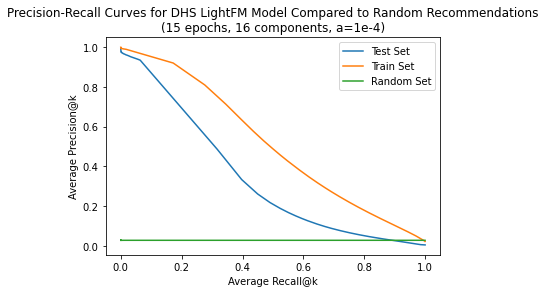

In [54]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.plot(recall_test_mean, precision_test_mean)
plt.plot(recall_train_mean, precision_train_mean)
plt.plot(random_recall_mean, random_precision_mean)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set', 'Random Set'])
plt.title('Precision-Recall Curves for DHS LightFM Model Compared to Random Recommendations\n(15 epochs, 16 components, a=1e-4)')

In [50]:
print(precision_test_mean[-1] + precision_train_mean[-1])
print(random_precision_mean[-1])
print(random_precision_mean[-1] - precision_test_mean[-1] - precision_train_mean[-1])

0.028978592076674935
0.028971246898510487
-7.345178164447352e-06


Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model with and without Random Recs\n(15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

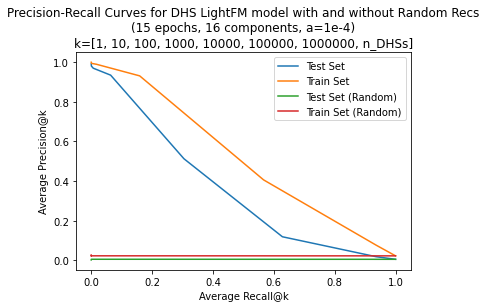

In [52]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.plot(recall_test_mean, precision_test_mean)
plt.plot(recall_train_mean, precision_train_mean)
plt.plot(random_recall_test_mean, random_precision_test_mean)
plt.plot(random_recall_train_mean, random_precision_train_mean)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set', 'Test Set (Random)', 'Train Set (Random)'])
plt.title('Precision-Recall Curves for DHS LightFM model with and without Random Recs\n(15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

In [53]:
random_auc_test = auc(random_recall_test_mean, random_precision_test_mean)
print(random_auc_test)
random_auc_train = auc(random_recall_train_mean, random_precision_train_mean)
print(random_auc_train)

0.005922702231745895
0.023303295392154928


In [1]:
# def pr_random_recs(model, test_data, train_data, k_vals):
#     n_rows, n_cols = test_data.shape
#     test_data_np = test_data.toarray()
#     train_data_np = train_data.toarray()
#     ordered_list = []
#     test_count_list = []
#     for row in range(n_rows):
#         #known positives in train set
#         train_kp = np.where(train_data_np[row]==1)[0]
#         #every DHS index
#         full_ind = np.arange(n_cols)
#         #only the DHS indices that are not known positives in the train set
#         test_only_ind = np.delete(full_ind, train_kp)
#         #For each biosample, the DHS values for each DHS that does not exist as known positive in train set
#         test_only_data = test_data_np[row, test_only_ind]
#         #For each biosample, counting the number of true positives in test set only
#         test_only_count = np.sum(test_only_data)
#         test_count_list.append(test_only_count)
#         #For each biosample, predicting scores for only dhs indices that are not known positives in train set
# #         scores = model.predict(row, test_only_ind)
#         #ordering scores
# #         ordered = np.argsort(-scores)
#         unordered = np.arange(len(test_only_ind))
#         np.random.shuffle(unordered)
# #         print(ordered)
# #         print(unordered)
#         #ordering DHS values that were not known positives in train set 
#         ordered_test_only = test_only_data[unordered]
#         ordered_list.append(ordered_test_only)
#     precision = []
#     recall = []
#     for k in k_vals:
#         k_precision = []
#         k_recall = []
#         for row in range(n_rows):
# #             k_precision.append(np.mean(ordered_list[row][:k])) #this is how we were going to calculate precision
#             #for each biosample, calculates precision for the top k DHS recs
#             count = np.sum(ordered_list[row][:k])
#             k_precision.append(count/k) #this is how lightFM calculates precision
#             k_recall.append(count/test_count_list[row])
#         precision.append(k_precision)
#         recall.append(k_recall)
#     return precision, recall